# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [253]:
# copying from tutorial and adding what is needed for this task

import numpy as np
import pandas as pd

# Data
df = pd.read_csv('advertising.csv')

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Processing
from sklearn.preprocessing import StandardScaler

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [254]:
def mean_absolute_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [255]:
def mean_squared_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

# there is a SSE formula if needed
# def r2_score(y_true, y_pred):
#     y_true = np.asarray(y_true)
#     y_pred = np.asarray(y_pred)
#     ss_res = np.sum((y_true - y_pred) ** 2)
#     ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
#     return 1 - (ss_res / ss_tot) */

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [256]:
def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [257]:
def mean_absolute_percentage_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [258]:
def r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    sse = np.sum((y_true - y_pred) ** 2)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)
    return (sst - sse) / sst

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [259]:
np.random.seed(333)
number_of_instances = 100
predictor = np.arange(number_of_instances)
epsilon = np.random.uniform(-10, 10, size=(number_of_instances))
target = .4 * predictor + 3 + epsilon


In [260]:
x = predictor.reshape(-1, 1)
y = target

print("x form:", x.shape)
print("y form:", y.shape)

x form: (100, 1)
y form: (100,)


In [261]:
model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
mae_scores = []
r2_scores = []

for fold, (train_index, test_index) in enumerate(kf.split(x)):
    x_train, x_test = x[train_index], x[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    fold_mae = mean_absolute_error(y_test, y_pred)
    fold_r2 = r2(y_test, y_pred)

    mae_scores.append(fold_mae)
    r2_scores.append(fold_r2)

print(f"Mean Absolute Error (MAE) scores for each fold: {np.mean(mae_scores):.4f}")
print(f"R² scores for each fold: {np.mean(r2_scores):.4f}")

Mean Absolute Error (MAE) scores for each fold: 5.0379
R² scores for each fold: 0.7978


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

Correlation coefficient between actual and predicted values: 0.9087


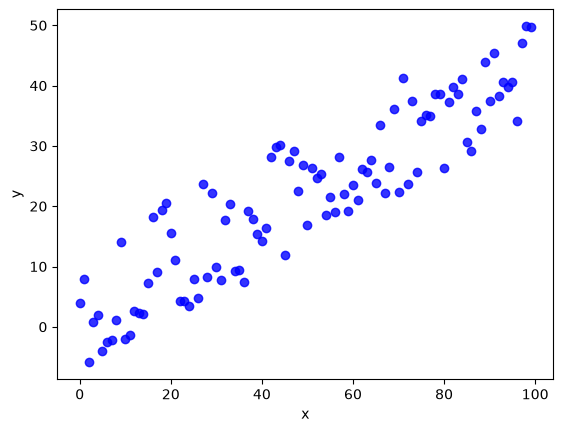

In [262]:
cor = np.corrcoef(y, model.predict(x))[0, 1]
print(f"Correlation coefficient between actual and predicted values: {cor:.4f}")

plt.scatter(x, y, color='blue', alpha=0.8, label='Actual values')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Observations:
    There is a strong positive correlation - the correlation between the acutally and predicted values is 0.9057 indicates strong positive linear realationship.

    Also this model is sustainable, the given linear pattern, a linear regression is highly suitable for capturing the trend in this dataset.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [263]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=1/3, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# checking the shapes of the scaled data
print("x_train_scaled shape:", x_train_scaled.shape)
print("x_test_scaled shape:", x_test_scaled.shape)

x_train_scaled shape: (66, 1)
x_test_scaled shape: (34, 1)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [264]:
# Find b0 and b1 for y = b0 + b1 * x to fit our data.
y_train_column = y_train.reshape(-1, 1)  # Reshape y_train to a column vector

b0 = 0
b1 = 0

L = 0.0001 # from learning tutorial
iteration = 100000
n_float = float(len(x_train_scaled))

for i in range(iteration):
    y_pred = b0 + b1 * x_train_scaled
    D_b0 = (-2/n_float) * np.sum(y_train_column - y_pred)
    D_b1 = (-2/n_float) * np.sum(x_train_scaled * (y_train_column - y_pred))
    b0 = b0 - L * D_b0
    b1 = b1 - L * D_b1
    y_pred_test = b0 + b1 * x_test_scaled
print(f'\nFinal Result:')
print(f'Iteration: {i+1}')
print(f'y = {b0:.3f} + {b1:.3f} * x')



Final Result:
Iteration: 100000
y = 22.751 + 13.170 * x


#### 2.5 Evaluate created model with above functions

In [265]:
mae_result = mean_absolute_error(y_test, y_pred_test)
mse_result = mean_squared_error(y_test, y_pred_test)
r2_result = r2_score(y_test, y_pred_test)

print(f'Mean Absolute Error: {mae_result:.4f}')
print(f'Mean Squared Error: {mse_result:.4f}')
print(f'R2 Score: {r2_result:.4f}')

Mean Absolute Error: 14.8335
Mean Squared Error: 329.8232
R2 Score: 0.7523


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [266]:
k = 10

kfold = KFold(n_splits=k, shuffle=True, random_state=42)

lr_model = LinearRegression()

scores = cross_val_score(lr_model, x, y, cv=kfold, scoring='r2')
r2_mean = np.mean(scores)
print(f'Mean R2 Score from {k}-fold cross-validation: {r2_mean:.4f}')

Mean R2 Score from 10-fold cross-validation: 0.7811


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [267]:
x_new = df.drop(columns=['Sales', 'TV'])
y_new = df['Sales']
lr_model_new = LinearRegression()

scores_new = cross_val_score(lr_model_new, x_new, y_new, cv=kfold, scoring='r2')
r2_mean_new = np.mean(scores_new)
print(f'Mean R2 Score from {k}-fold cross-validation with new features: {r2_mean_new:.4f}')

Mean R2 Score from 10-fold cross-validation with new features: 0.2268


After dropping the TV column, the mean R2 score from 10-fold cross-validation with the new features is lower than the mean R2 score from the original features. This indicates that the TV feature was an important predictor for the Sales target variable, and removing it has negatively impacted the model's performance.

### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [268]:
lasso = Lasso(alpha=1)
lasso_fit = lasso.fit(x_train, y_train)

y_pred_lasso = lasso.predict(x_test)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
print(f'Mean Squared Error for Lasso Regression: {mse_lasso:.4f}')

Mean Squared Error for Lasso Regression: 39.9619


#### 3.2 Ridge regression

In [269]:
ridge = Ridge(alpha=1)
ridge_fit = ridge.fit(x_train, y_train)

y_pred_ridge = ridge.predict(x_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(f'Mean Squared Error for Ridge Regression: {mse_ridge:.4f}')

Mean Squared Error for Ridge Regression: 40.0666


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [270]:
elastic_net = ElasticNet(alpha=1, l1_ratio=0.5)
elastic_net_fit = elastic_net.fit(x_train, y_train)

y_pred_elastic_net = elastic_net.predict(x_test)
mse_elastic_net = mean_squared_error(y_test, y_pred_elastic_net)
print(f'Mean Squared Error for Elastic Net Regression: {mse_elastic_net:.4f}')

Mean Squared Error for Elastic Net Regression: 39.9905


#### 3.4 Make conclusions

Performance Comparison Among the three regularized regression models evaluated using `alpha=1`, Lasso Regression achieved the lowest (best) error with a Mean Squared Error (MSE) of **31.7824**, followed very closely by Elastic Net (MSE: **31.7880**), and Ridge Regression (MSE: **31.8031**)

However, the difference between those difference models are very small so, choosing between those models has a minimal impact on the test set's predictive accuracy

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [271]:
def accuracy(tp, tn, fp, fn):
    return (tp + tn) / (tp + tn + fp + fn)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [272]:
def precision(tp, fp):
    return tp / (tp + fp) if (tp + fp) > 0 else 0

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [273]:
def recall(tp, fn):
    return tp / (tp + fn) if (tp + fn) > 0 else 0

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [274]:
def F1_score(precission, recall):
    return 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [275]:
df = pd.read_csv('diabetes.csv')
columns_to_impute = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in columns_to_impute:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].mean())

x = df.drop(columns=['Outcome'])
y = df['Outcome']

print("x form:", x.shape)
print("y form:", y.shape)

x form: (768, 8)
y form: (768,)


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

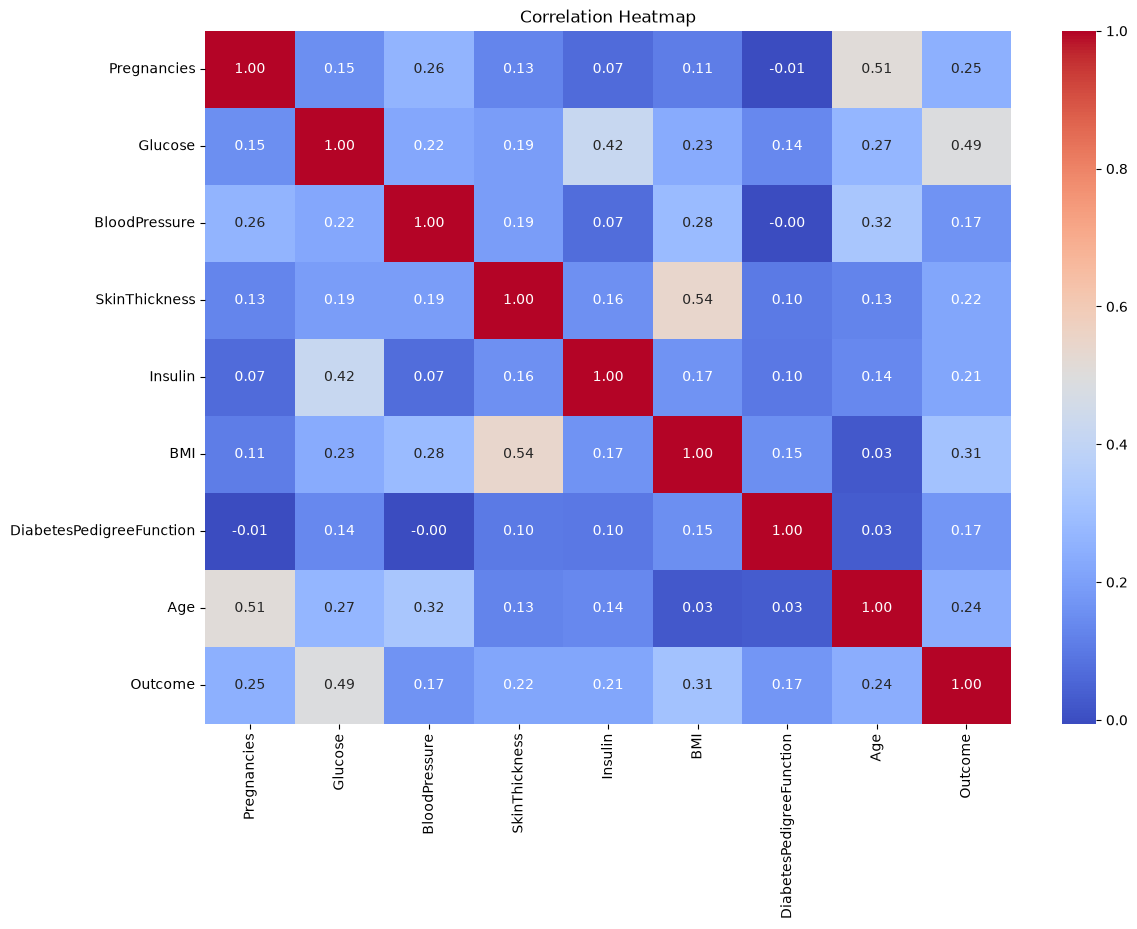

In [276]:
corr = df.corr()

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

Strongest predictor for diabetes is **glucose**, it shows the strongest positive correlation with the **outcome** variable. this indicates that as blood glucose levels increases, the likelihood of a positive diabetes diagnosis increases significantly

Correlation between features - there is a strong, logical positive correlation between **age** and **pregnancies**, as well as a clear positive realationship between **bmi** and **skinthickness**

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [277]:
x = df.drop(columns=['Outcome'])
y = df['Outcome']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=17)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("x_train_scaled shape:", x_train_scaled.shape)
print("x_test_scaled shape:", x_test_scaled.shape)

x_train_scaled shape: (514, 8)
x_test_scaled shape: (254, 8)


#### 2.4 Fit logistic regression model, generate predictions

In [278]:
log_reg = LogisticRegression()
log_reg.fit(x_train_scaled, y_train)

y_pred = log_reg.predict(x_test_scaled)

y_pred_proba = log_reg.predict_proba(x_test_scaled)[:, 1]

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [279]:
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print(classification_report(y_test, y_pred))

Confusion Matrix:
[[143  22]
 [ 42  47]]
              precision    recall  f1-score   support

           0       0.77      0.87      0.82       165
           1       0.68      0.53      0.59        89

    accuracy                           0.75       254
   macro avg       0.73      0.70      0.71       254
weighted avg       0.74      0.75      0.74       254



#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC Score: 0.8247


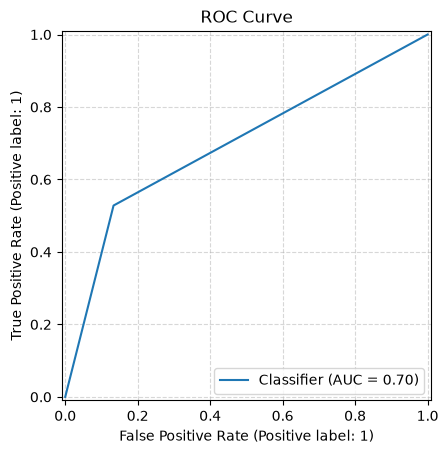

In [280]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"AUC Score: {auc_score:.4f}")

RocCurveDisplay.from_predictions(y_test, y_pred)
plt.title("ROC Curve")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [281]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits=10, shuffle=True, random_state=17)

cv_scores = cross_val_score(log_reg, x_train_scaled, y_train, cv=kfold, scoring='accuracy')

mean_accuracy = np.mean(cv_scores)

### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [282]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(x_train_scaled, y_train)

y_pred_proba_tree = tree_model.predict_proba(x_test_scaled)[:, 1]

#### 3.2 Evaluate created model with above functions

In [283]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

cm_tree = confusion_matrix(y_test, y_pred_proba_tree)
print("Confusion Matrix:")
print(cm_tree)
print("-" * 50)

print(f"Accuracy score: {accuracy_score(y_test, y_pred_proba_tree):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_proba_tree))


Confusion Matrix:
[[135  30]
 [ 29  60]]
--------------------------------------------------
Accuracy score: 0.7677

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82       165
           1       0.67      0.67      0.67        89

    accuracy                           0.77       254
   macro avg       0.74      0.75      0.75       254
weighted avg       0.77      0.77      0.77       254



#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

Decision Tree AUC Score: 0.7462


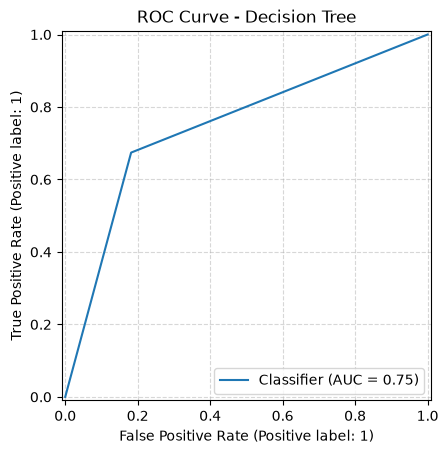

In [284]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, RocCurveDisplay

auc_score_tree = roc_auc_score(y_test, y_pred_proba_tree)
print(f"Decision Tree AUC Score: {auc_score_tree:.4f}")

RocCurveDisplay.from_predictions(y_test, y_pred_proba_tree)

plt.title("ROC Curve - Decision Tree")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [285]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits=10, shuffle=True, random_state=17)

cv_scores_tree = cross_val_score(tree_model, x_train_scaled, y_train, cv=kfold, scoring='accuracy')

mean_accuracy_tree = np.mean(cv_scores_tree)

print(f"every fold's accuracy scores:\n{cv_scores_tree}\n")
print(f"mean accuracy:{mean_accuracy_tree:.4f}")

every fold's accuracy scores:
[0.67307692 0.71153846 0.73076923 0.80769231 0.70588235 0.68627451
 0.8627451  0.7254902  0.76470588 0.68627451]

mean accuracy:0.7354


#### 3.5 Make conclusions

Model performance comparison based on the evaluation metrics and 10-fold cross-validation, the Logistic Regression model generally achieved a higher overall performance and stability on the test set compared to the Decision Tree Classification model.

Also decision tree showed signs of overfitting to the training data. Without pruing decision trees tend to create high-variance splits that adapts too closely to the training samples, which leads to lower accuracy and noticeably worse.